# What Actually Wins AFL Games?
**AFL match and player data, 2012 to 2025** · Python (pandas, matplotlib) · Tableau

I looked at 14 seasons of AFL data from the point of view of a club analyst, to answer six questions:

1. Is home ground advantage real, and is it bigger when the visitors travel interstate?
2. Which team stats separate winners from losers?
3. Does rain change how the game is played?
4. How safe is a half time lead?
5. What drives crowd sizes?
6. Which players are the most consistent ball winners?

**Data:** Australian Football League (AFL) Database on Kaggle (stoney71), sourced from afltables.com and footywire.com.
`games.csv` has one row per match, `stats.csv` one row per player per match, and `players.csv` one row per player.

## 1. Setup and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.figsize"] = (9, 4.5)

DATA = Path("data")
OUT = Path("tableau")          # cleaned files for my Tableau dashboard
OUT.mkdir(exist_ok=True)

# Scores are stored as goals.behinds (e.g. 14.10), so I read them as text.
# If pandas read them as numbers, 14.10 would turn into 14.1.
score_cols = [f"{side}TeamScore{q}" for side in ["Home", "Away"] for q in ["QT", "HT", "3QT", "FT"]]

games = pd.read_csv(DATA / "games.csv", dtype={c: str for c in score_cols})
stats = pd.read_csv(DATA / "stats.csv", dtype={"Subs": str})
players = pd.read_csv(DATA / "players.csv")

print(f"games:   {len(games):,} rows")
print(f"stats:   {len(stats):,} rows")
print(f"players: {len(players):,} rows")

games:   2,879 rows
stats:   128,938 rows
players: 1,825 rows


## 2. Check data quality

In [2]:
# Games per season (2020 was shortened by COVID)
print(games["Year"].value_counts().sort_index().to_dict(), "\n")

# Missing values
print("Missing values in games:", games.isna().sum()[lambda x: x > 0].to_dict(), "\n")

# GameIds should be unique
print("Rows sharing a GameId:", games["GameId"].duplicated(keep=False).sum())

# Exact duplicate rows in player stats
print("Duplicate stat rows:", stats.duplicated().sum())

# Scores that lost their trailing zero (e.g. 14.10 saved as 14.1)
ft_goals = games["HomeTeamScoreFT"].str.split(".").str[0].astype(int)
ft_behinds = games["HomeTeamScoreFT"].str.split(".").str[1].astype(int)
print("Home scores that don't add up:", (ft_goals * 6 + ft_behinds != games["HomeTeamScore"]).sum())

{2012: 207, 2013: 207, 2014: 207, 2015: 206, 2016: 207, 2017: 207, 2018: 207, 2019: 207, 2020: 162, 2021: 207, 2022: 207, 2023: 216, 2024: 216, 2025: 216} 

Missing values in games: {'MaxTemp': 11, 'MinTemp': 11, 'Rainfall': 23} 

Rows sharing a GameId: 6
Duplicate stat rows: 138
Home scores that don't add up: 317


**What I found:**
* 3 GameIds are reused for 6 different 2024 Opening Round matches.
* 138 exact duplicate rows in the player stats.
* Many scores lost their trailing zero in the source file (14.10 became 14.1), so the behinds are wrong.
* Attendance is stored as text with commas, and some 2020 games show 0 because crowds weren't allowed.
* A few games are missing weather data.

## 3. Clean the games table

In [3]:
g = games.copy()

# The reused 2024 GameIds belong to different matches, so I make them unique
g["GameId"] = g["GameId"] + g.groupby("GameId").cumcount().map(lambda n: "" if n == 0 else f"_{n + 1}")

# Dates, crowds and kick off times
g["Date"] = pd.to_datetime(g["Date"])
g["Attendance"] = pd.to_numeric(g["Attendance"].astype(str).str.replace(",", ""), errors="coerce")
g.loc[g["Attendance"] == 0, "Attendance"] = np.nan          # 0 means no crowd was allowed
g["StartHour"] = pd.to_datetime(g["StartTime"], format="%I:%M %p").dt.hour
g["TimeSlot"] = pd.cut(g["StartHour"], bins=[0, 15, 18, 24], labels=["Day", "Twilight", "Night"], right=False)

finals = ["Qualifying Final", "Elimination Final", "Semi Final", "Preliminary Final", "Grand Final"]
g["Stage"] = np.where(g["Round"].isin(finals), "Finals", "Regular season")

# Results
g["Margin"] = g["HomeTeamScore"] - g["AwayTeamScore"]          # positive means the home team won
g["Result"] = np.select([g["Margin"] > 0, g["Margin"] < 0], ["Home win", "Away win"], "Draw")
g["TotalPoints"] = g["HomeTeamScore"] + g["AwayTeamScore"]

**Fixing the half time scores.** Because trailing zeros were lost, a half time score of `5.1` could really be 5 goals 1 behind or 5 goals 10 behinds.
I use three simple rules to decide:
* Full time behinds are known exactly: final score minus goals × 6.
* Behinds can never go down as a game goes on, so half time can't be lower than quarter time or higher than three quarter time or full time.
* If both options are still possible, I pick the one closest to half of the full time behinds.

In [4]:
def behinds(text):
    return int(text.split(".")[1])

def goals(text):
    return int(text.split(".")[0])

def half_time_points(row, side):
    ht = row[f"{side}TeamScoreHT"]
    b = behinds(ht)
    ft_behinds = row[f"{side}TeamScore"] - goals(row[f"{side}TeamScoreFT"]) * 6
    if b not in (1, 2):                                     # only 1 and 2 could have lost a zero
        return goals(ht) * 6 + b

    alt = b * 10
    q3 = behinds(row[f"{side}TeamScore3QT"])
    q3_max = q3 * 10 if q3 in (1, 2) else q3
    qt = behinds(row[f"{side}TeamScoreQT"])

    if alt > ft_behinds or alt > q3_max:                    # 10 or 20 is impossible
        best = b
    elif b < qt:                                            # 1 or 2 is impossible
        best = alt
    else:                                                   # both possible, pick the closest fit
        best = alt if abs(alt - ft_behinds / 2) < abs(b - ft_behinds / 2) else b
    return goals(ht) * 6 + best

g["HomeHT"] = g.apply(half_time_points, side="Home", axis=1)
g["AwayHT"] = g.apply(half_time_points, side="Away", axis=1)
g["HalfTimeMargin"] = g["HomeHT"] - g["AwayHT"]

print("Half time margins calculated for", g["HalfTimeMargin"].notna().sum(), "games")

Half time margins calculated for 2879 games


In [5]:
# Which state each club and venue is in, so I can tell when the away team has travelled
team_state = {
    "Adelaide": "SA", "Port Adelaide": "SA", "Brisbane": "QLD", "Gold Coast": "QLD",
    "Fremantle": "WA", "West Coast": "WA", "Sydney": "NSW", "Greater Western Sydney": "NSW",
}   # every other club is Victorian

venue_state = {
    "MCG": "VIC", "Docklands": "VIC", "Kardinia Park": "VIC", "Eureka Stadium": "VIC",
    "Adelaide Oval": "SA", "Football Park": "SA", "Norwood Oval": "SA", "Summit Sports Park": "SA", "Barossa Oval": "SA",
    "Gabba": "QLD", "Carrara": "QLD", "Cazaly's Stadium": "QLD", "Riverway Stadium": "QLD",
    "Perth Stadium": "WA", "Subiaco": "WA", "Hands Oval": "WA",
    "SCG": "NSW", "Sydney Showground": "NSW", "Stadium Australia": "NSW", "Blacktown": "NSW",
    "York Park": "TAS", "Bellerive Oval": "TAS", "Manuka Oval": "ACT",
    "Marrara Oval": "NT", "Traeger Park": "NT", "Wellington": "NZ", "Jiangwan Stadium": "China",
}

g["AwayState"] = g["AwayTeam"].map(team_state).fillna("VIC")
g["VenueState"] = g["Venue"].map(venue_state)
g["AwayTravelled"] = np.where(g["AwayState"] != g["VenueState"], "Away team travelled interstate", "Same state")

# Rain groups
g["RainCategory"] = pd.cut(g["Rainfall"], bins=[-0.1, 0, 5, 1000],
                           labels=["Dry (0 mm)", "Light (0.1 to 5 mm)", "Wet (over 5 mm)"])

print("Venues without a state:", g.loc[g["VenueState"].isna(), "Venue"].unique())
g[["GameId", "Date", "HomeTeam", "AwayTeam", "Venue", "Margin", "Result", "HalfTimeMargin", "AwayTravelled"]].head()

Venues without a state: []


,GameId,Date,HomeTeam,AwayTeam,Venue,Margin,Result,HalfTimeMargin,AwayTravelled
0,2012R0101,2012-03-24,Greater Western Sydney,Sydney,Stadium Australia,-63,Away win,-31,Same state
1,2012R0102,2012-03-29,Richmond,Carlton,MCG,-44,Away win,-19,Same state
2,2012R0103,2012-03-30,Hawthorn,Collingwood,MCG,22,Home win,15,Same state
3,2012R0104,2012-03-31,Melbourne,Brisbane,MCG,-41,Away win,-4,Away team travelled interstate
4,2012R0105,2012-03-31,Gold Coast,Adelaide,Carrara,-69,Away win,-43,Away team travelled interstate


## 4. Build team stats for each match
I total each team's player stats per match, then link them to the games table.

In 2024 the GameIds in `stats.csv` don't line up with `games.csv`, so I only keep a match when both teams agree in the two files.
I also use the official scores from `games.csv`, because rushed behinds aren't credited to any player.

In [6]:
s = stats.drop_duplicates().copy()

stat_cols = ["Disposals", "Marks", "Tackles", "Inside50s", "Clearances", "ContestedPossessions",
             "UncontestedPossessions", "MarksInside50", "Rebounds", "Clangers", "FreesAgainst"]

team = s.groupby(["GameId", "Year", "Team"], as_index=False)[stat_cols].sum()

# Link to games and keep only matches where both teams agree
team = team.merge(g[["GameId", "Venue", "RainCategory", "HomeTeam", "AwayTeam", "HomeTeamScore", "AwayTeamScore"]], on="GameId")
team = team[(team["Team"] == team["HomeTeam"]) | (team["Team"] == team["AwayTeam"])]
team = team[team.groupby("GameId")["Team"].transform("nunique") == 2]

# Each team's score, opponent and result
team["IsHome"] = team["Team"] == team["HomeTeam"]
team["Opponent"] = np.where(team["IsHome"], team["AwayTeam"], team["HomeTeam"])
team["Points"] = np.where(team["IsHome"], team["HomeTeamScore"], team["AwayTeamScore"])
team["OppPoints"] = np.where(team["IsHome"], team["AwayTeamScore"], team["HomeTeamScore"])
team["Won"] = (team["Points"] > team["OppPoints"]).astype(int)

# Add the opponent's stats, then the difference for each stat
opp = team[["GameId", "Team"] + stat_cols].rename(columns={"Team": "Opponent", **{c: f"Opp{c}" for c in stat_cols}})
team = team.merge(opp, on=["GameId", "Opponent"])
for c in stat_cols:
    team[f"Diff{c}"] = team[c] - team[f"Opp{c}"]

team = team[team["Points"] != team["OppPoints"]]          # leave out draws

print(f"Matches linked (draws excluded): {team['GameId'].nunique():,} of {len(g):,}")

Matches linked (draws excluded): 2,654 of 2,879


## 5. Analysis

### Q1. Is home ground advantage real?
I leave out 2020, when most games were played in hubs.

Overall home win rate: 56.6%
                                Games  HomeWinRate  AvgHomeMargin
AwayTravelled                                                    
Away team travelled interstate   1817        0.582          8.229
Same state                        881        0.535          2.054


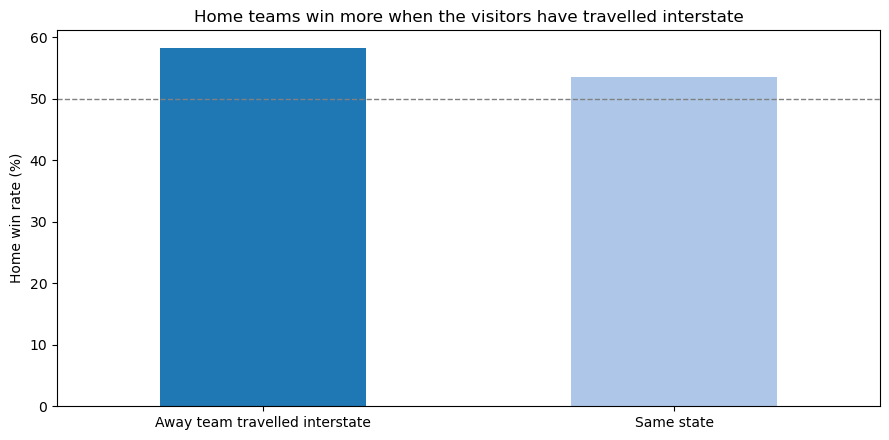

In [7]:
hg = g[(g["Year"] != 2020) & (g["Result"] != "Draw")]
print(f"Overall home win rate: {(hg['Result'] == 'Home win').mean():.1%}")

q1 = hg.groupby("AwayTravelled").agg(
    Games=("GameId", "count"),
    HomeWinRate=("Result", lambda r: (r == "Home win").mean()),
    AvgHomeMargin=("Margin", "mean"),
).round(3)
print(q1)

ax = (q1["HomeWinRate"] * 100).plot(kind="bar", color=["#1f77b4", "#aec7e8"], rot=0)
ax.axhline(50, color="grey", linestyle="--", linewidth=1)
ax.set(title="Home teams win more when the visitors have travelled interstate", ylabel="Home win rate (%)", xlabel="")
plt.tight_layout(); plt.show()

### Q2. Which stats separate winners from losers?
For each stat, when a team has more of it than the opposition, how often does it win?

                      Stat  WinRateWhenAhead
7            MarksInside50             0.778
3                Inside50s             0.723
0                Disposals             0.717
5     ContestedPossessions             0.703
1                    Marks             0.692
6   UncontestedPossessions             0.682
4               Clearances             0.623
2                  Tackles             0.555
10            FreesAgainst             0.455
8                 Rebounds             0.410
9                 Clangers             0.375


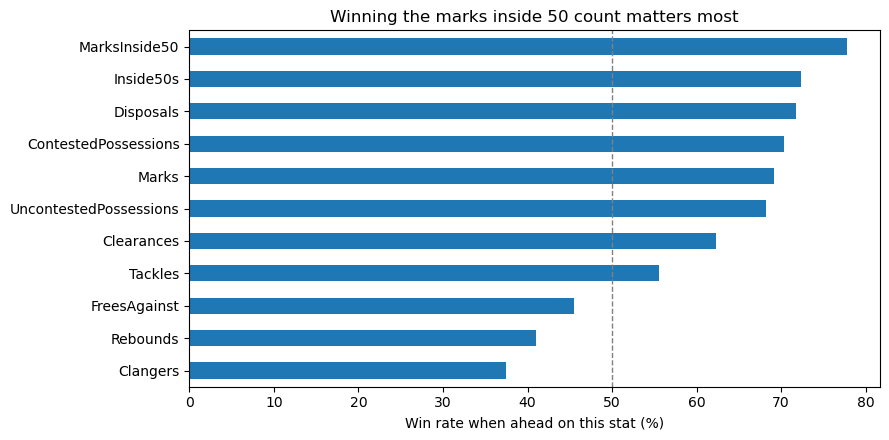

In [8]:
q2 = pd.DataFrame({
    "Stat": stat_cols,
    "WinRateWhenAhead": [team.loc[team[f"Diff{c}"] > 0, "Won"].mean() for c in stat_cols],
}).sort_values("WinRateWhenAhead", ascending=False).round(3)
print(q2)

ax = (q2.set_index("Stat")["WinRateWhenAhead"] * 100).sort_values().plot(kind="barh", color="#1f77b4")
ax.axvline(50, color="grey", linestyle="--", linewidth=1)
ax.set(title="Winning the marks inside 50 count matters most", xlabel="Win rate when ahead on this stat (%)", ylabel="")
plt.tight_layout(); plt.show()

Anything near 50% doesn't predict the result. Stats below 50% go with **losing**:
a team racking up rebounds is usually under pressure, and clangers are mistakes.

### Q3. Does rain change the game?
Docklands has a roof, so I leave it out.

                     Games  AvgTotalPoints  ContestedShare  AvgTackles  \
RainCategory                                                             
Dry (0 mm)            1349           168.4           0.388        61.5   
Light (0.1 to 5 mm)    657           164.5           0.397        64.7   
Wet (over 5 mm)        255           160.2           0.407        67.5   

                     AvgMarks  
RainCategory                   
Dry (0 mm)               88.9  
Light (0.1 to 5 mm)      86.5  
Wet (over 5 mm)          82.4  


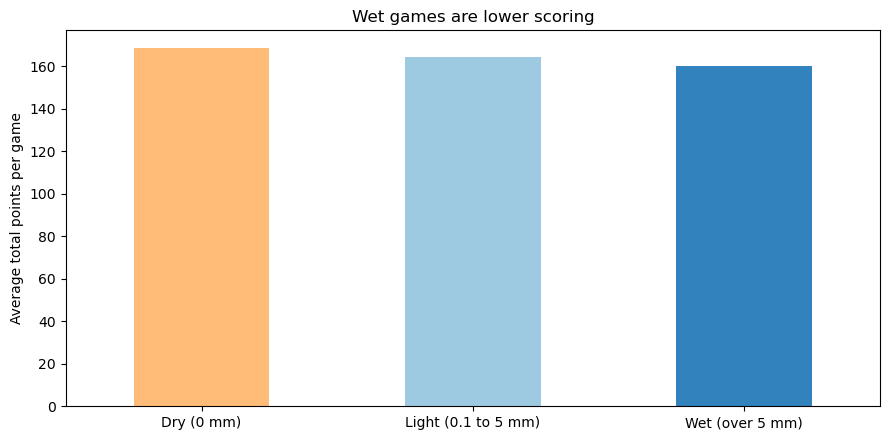

In [9]:
outdoor = g[(g["Venue"] != "Docklands") & g["RainCategory"].notna()]
q3 = outdoor.groupby("RainCategory", observed=True).agg(Games=("GameId", "count"),
                                                         AvgTotalPoints=("TotalPoints", "mean")).round(1)

# Is the game more contested in the wet?
t = team[team["Venue"] != "Docklands"].copy()
t["ContestedShare"] = t["ContestedPossessions"] / (t["ContestedPossessions"] + t["UncontestedPossessions"])
q3["ContestedShare"] = t.groupby("RainCategory", observed=True)["ContestedShare"].mean().round(3)
q3["AvgTackles"] = t.groupby("RainCategory", observed=True)["Tackles"].mean().round(1)
q3["AvgMarks"] = t.groupby("RainCategory", observed=True)["Marks"].mean().round(1)
print(q3)

ax = q3["AvgTotalPoints"].plot(kind="bar", color=["#ffbb78", "#9ecae1", "#3182bd"], rot=0)
ax.set(title="Wet games are lower scoring", ylabel="Average total points per game", xlabel="")
plt.tight_layout(); plt.show()

### Q4. How safe is a half time lead?

          Games  LeaderWinRate
LeadSize                      
1 to 6      542          0.622
7 to 12     522          0.686
13 to 24    796          0.817
25 to 36    524          0.920
37+         432          0.986


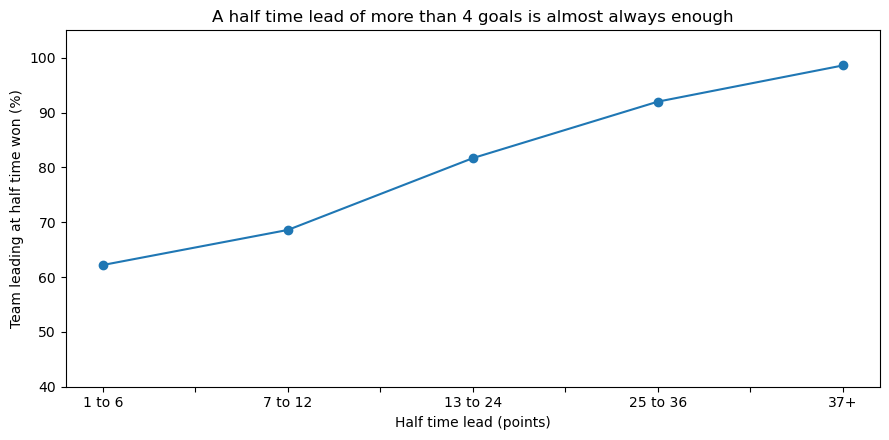

In [10]:
ht = g[(g["Result"] != "Draw") & (g["HalfTimeMargin"] != 0)].copy()
ht["LeadSize"] = pd.cut(ht["HalfTimeMargin"].abs(), bins=[0, 6, 12, 24, 36, 200],
                        labels=["1 to 6", "7 to 12", "13 to 24", "25 to 36", "37+"])
ht["LeaderWon"] = np.where(ht["HalfTimeMargin"] > 0, ht["Result"] == "Home win", ht["Result"] == "Away win")

q4 = ht.groupby("LeadSize", observed=True).agg(Games=("GameId", "count"),
                                              LeaderWinRate=("LeaderWon", "mean")).round(3)
print(q4)

ax = (q4["LeaderWinRate"] * 100).plot(marker="o", color="#1f77b4")
ax.set(title="A half time lead of more than 4 goals is almost always enough",
       ylabel="Team leading at half time won (%)", xlabel="Half time lead (points)", ylim=(40, 105))
plt.tight_layout(); plt.show()

### Q5. What drives crowd sizes?
I leave out 2020 and 2021, when crowds were limited by COVID.

                   Games  AvgCrowd
Venue                             
MCG                  609   55313.0
Perth Stadium        139   44880.0
Adelaide Oval        245   41110.0
Subiaco              140   35469.0
SCG                  128   32387.0
Docklands            541   30534.0
Football Park         46   29707.0
Kardinia Park        100   25870.0
Gabba                140   23274.0
Carrara              118   13913.0
York Park             48   13290.0
Sydney Showground     96   11261.0
Manuka Oval           37   10642.0
Bellerive Oval        36   10096.0 

TimeSlot
Day         30729.0
Twilight    33969.0
Night       40087.0
Name: Attendance, dtype: float64 

Stage
Finals            64834.0
Regular season    33825.0
Name: Attendance, dtype: float64


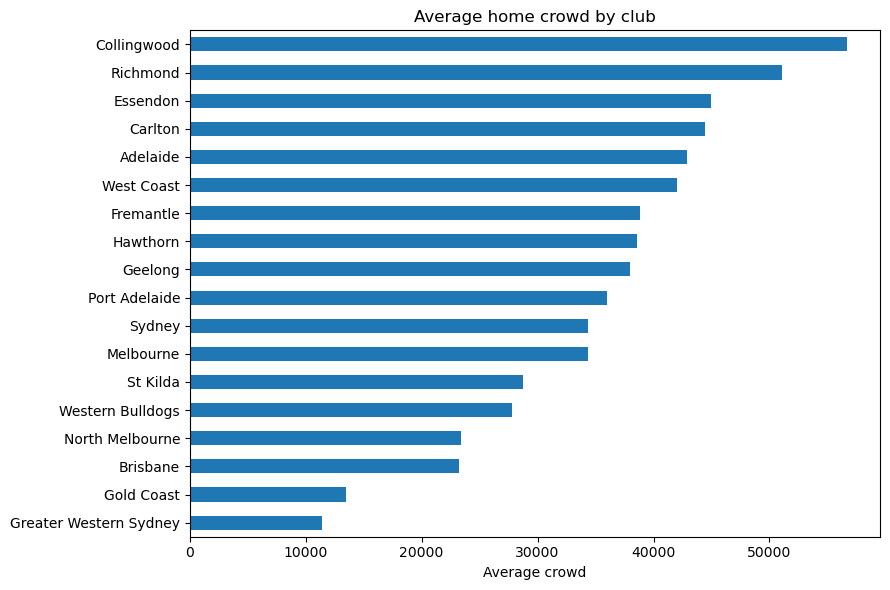

In [11]:
cr = g[~g["Year"].isin([2020, 2021]) & g["Attendance"].notna()]

venues = cr.groupby("Venue").agg(Games=("GameId", "count"), AvgCrowd=("Attendance", "mean"))
print(venues[venues["Games"] >= 20].sort_values("AvgCrowd", ascending=False).round(0), "\n")
print(cr.groupby("TimeSlot", observed=True)["Attendance"].mean().round(0), "\n")
print(cr.groupby("Stage")["Attendance"].mean().round(0))

ax = cr.groupby("HomeTeam")["Attendance"].mean().sort_values().plot(kind="barh", color="#1f77b4", figsize=(9, 6))
ax.set(title="Average home crowd by club", xlabel="Average crowd", ylabel="")
plt.tight_layout(); plt.show()

### Q6. Which players are the most consistent ball winners?
Players with 50+ games where they played at least 80% of the match.
I measure consistency with the coefficient of variation (standard deviation divided by average). Lower is more consistent.

           PlayerName            Position  Games  AvgDisposals  Consistency
89       Matt Priddis            Midfield    112         28.12         0.17
362       Ollie Wines            Midfield     60         27.22         0.17
88   Scott Pendlebury            Midfield    211         27.39         0.18
478    Clayton Oliver            Midfield    135         30.15         0.19
21       Sam Mitchell            Midfield    128         28.77         0.19
26    Brendon Goddard  Defender, Midfield    137         25.39         0.19
197    Michael Barlow   Midfield, Forward     75         26.48         0.20
601         Sam Walsh            Midfield    105         27.94         0.20
335       Brad Crouch            Midfield     69         27.74         0.20
11     Scott Thompson            Midfield     88         27.93         0.20


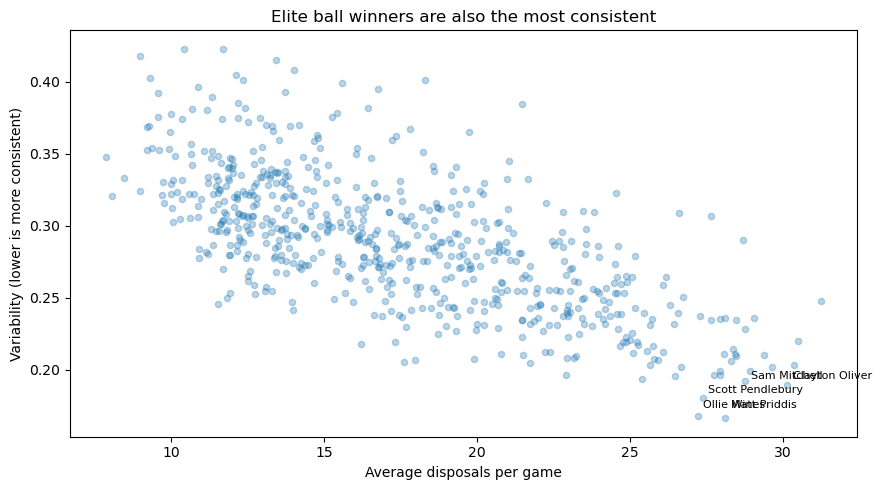

In [ ]:
p = s[s["%Played"] >= 80]
q6 = p.groupby(["PlayerId", "PlayerName"]).agg(Games=("GameId", "count"),
                                               AvgDisposals=("Disposals", "mean"),
                                               StdDisposals=("Disposals", "std")).reset_index()
q6 = q6[q6["Games"] >= 50]
q6["Consistency"] = q6["StdDisposals"] / q6["AvgDisposals"]
q6 = q6.merge(players[["PlayerId", "Position"]], on="PlayerId", how="left")

top = q6[q6["AvgDisposals"] >= 25].sort_values("Consistency").head(10).round(2)
print(top[["PlayerName", "Position", "Games", "AvgDisposals", "Consistency"]])

ax = q6.plot.scatter(x="AvgDisposals", y="Consistency", alpha=0.3, color="#1f77b4", figsize=(9, 5))
# I label only the top 3 and spread the labels out so they don't overlap
for (_, r), offset in zip(top.head(3).iterrows(), [(-90, 15), (10, -15), (10, 15)]):
    ax.annotate(r["PlayerName"], (r["AvgDisposals"], r["Consistency"]), fontsize=8,
                xytext=offset, textcoords="offset points", arrowprops=dict(arrowstyle="-", color="grey"))
ax.set(title="Elite ball winners are also the most consistent",
       xlabel="Average disposals per game", ylabel="Variability (lower is more consistent)")
plt.tight_layout(); plt.show()

## 6. Export clean files for Tableau

In [13]:
g[["GameId", "Year", "Round", "Stage", "Date", "StartHour", "TimeSlot", "Venue", "VenueState",
   "HomeTeam", "AwayTeam", "AwayTravelled", "HomeTeamScore", "AwayTeamScore", "Margin", "Result",
   "TotalPoints", "HalfTimeMargin", "Attendance", "Rainfall", "RainCategory"]].to_csv(OUT / "games_clean.csv", index=False)

team.drop(columns=["HomeTeam", "AwayTeam", "HomeTeamScore", "AwayTeamScore"]).to_csv(OUT / "team_games.csv", index=False)
q2.to_csv(OUT / "stats_that_win.csv", index=False)
q6.to_csv(OUT / "player_consistency.csv", index=False)

for f in sorted(OUT.glob("*.csv")):
    print(f.name)

games_clean.csv
player_consistency.csv
stats_that_win.csv
team_games.csv


## 7. Key findings
1. **Home advantage:** home teams won 56.6% of games. When the visitors had travelled interstate, the home team won 58.2% with an average margin of 8 points, compared with 53.5% and 2 points when both teams were from the same state.
2. **Stats that win:** teams with more marks inside 50 won 77.8% of the time, followed by inside 50s (72.3%). More rebounds (41%) and clangers (37.5%) went with losing.
3. **Rain:** wet games averaged 160 points compared with 168 in dry games, with a higher share of contested possessions, more tackles and fewer marks.
4. **Half time leads:** a lead of 1 to 6 points held up 62% of the time. A lead of 25 to 36 points held up 92% of the time, and 37+ points 98.6%.
5. **Crowds:** the MCG averaged over 55,000. Night games drew about 40,000 compared with 31,000 for day games, and finals averaged nearly double the regular season.
6. **Consistency:** the most consistent high volume ball winners were midfielders such as Matt Priddis, Ollie Wines and Scott Pendlebury.